# Regression and Evaluation

### Dataset
#### California Housing dataset


In [55]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split

### 1. Data Loading and Preprocessing

In [4]:
housing = fetch_california_housing()
df=pd.DataFrame(housing.data,columns=housing.feature_names)
df["MedHouseVal"] = housing.target
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
df.shape

(20640, 9)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [7]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [8]:
X=df.drop(columns=["MedHouseVal"])
y=df["MedHouseVal"]
X.shape

(20640, 8)

In [9]:
y.shape

(20640,)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [19]:
train_df = X_train.copy()
train_df["MedHouseVal"] = y_train
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,16512.0,3.880754,1.904294,0.499900,2.566700,3.545800,4.773175,15.000100
HouseAge,16512.0,28.608285,12.602499,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,16512.0,5.435235,2.387375,0.888889,4.452055,5.235874,6.061037,141.909091
AveBedrms,16512.0,1.096685,0.433215,0.333333,1.006508,1.049286,1.100348,25.636364
Population,16512.0,1426.453004,1137.056380,3.000000,789.000000,1167.000000,1726.000000,35682.000000
AveOccup,16512.0,3.096961,11.578744,0.692308,2.428799,2.817240,3.280000,1243.333333
Latitude,16512.0,35.643149,2.136665,32.550000,33.930000,34.260000,37.720000,41.950000
Longitude,16512.0,-119.582290,2.005654,-124.350000,-121.810000,-118.510000,-118.010000,-114.310000
MedHouseVal,16512.0,2.071947,1.156226,0.149990,1.198000,1.798500,2.651250,5.000010


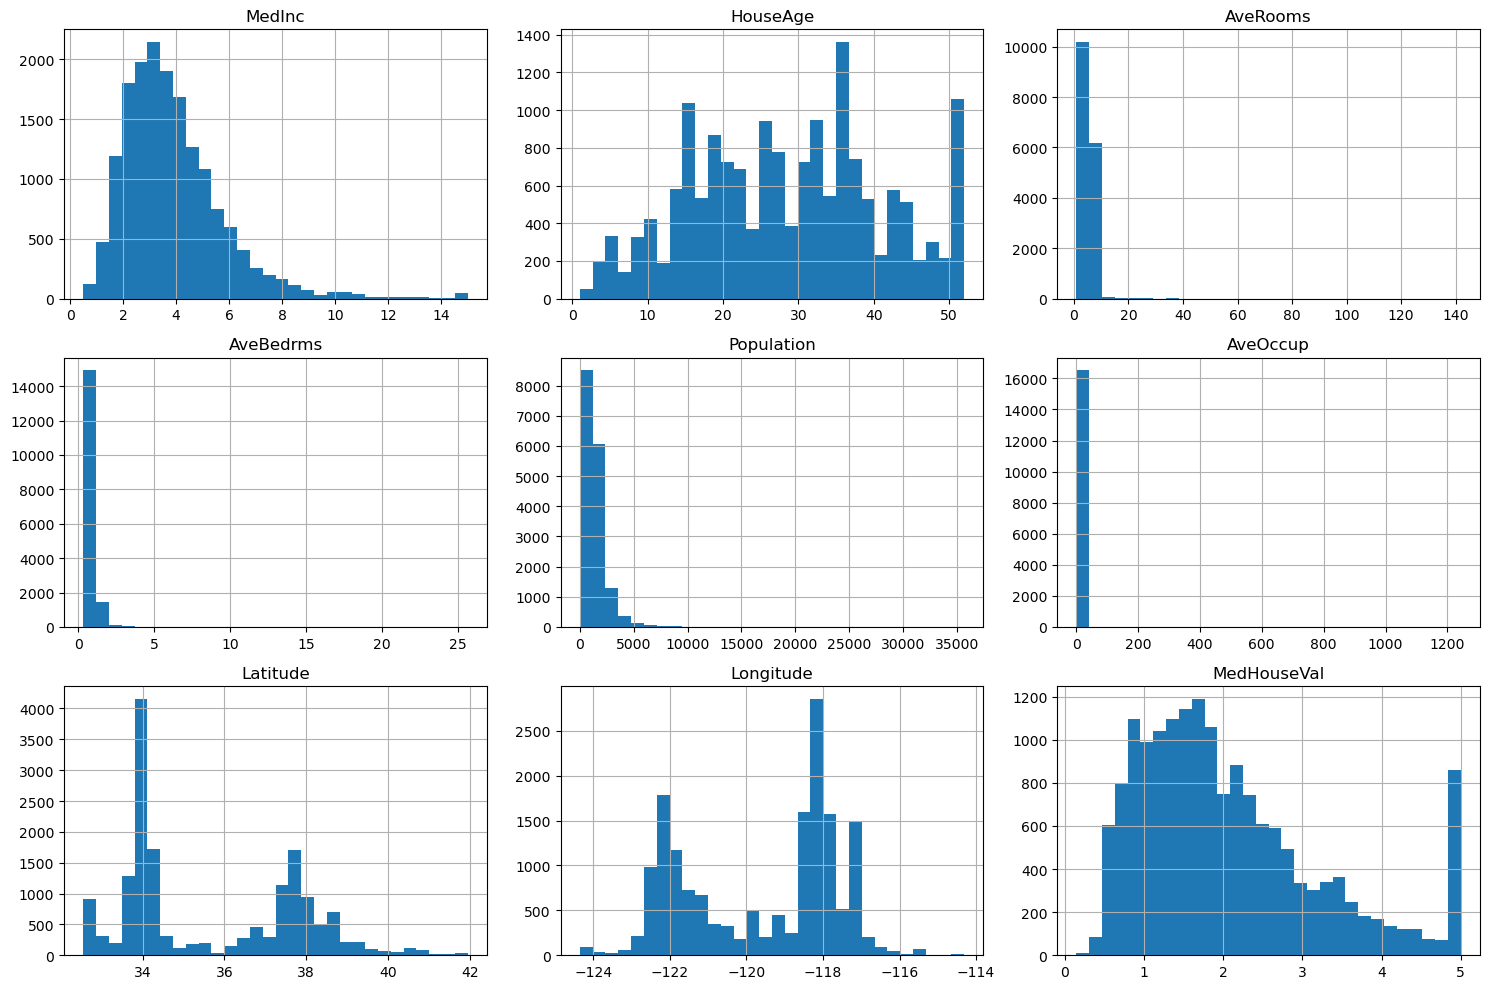

In [21]:
train_df.hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

count    16512.000000
mean         3.096961
std         11.578744
min          0.692308
25%          2.428799
50%          2.817240
75%          3.280000
max       1243.333333
Name: AveOccup, dtype: float64


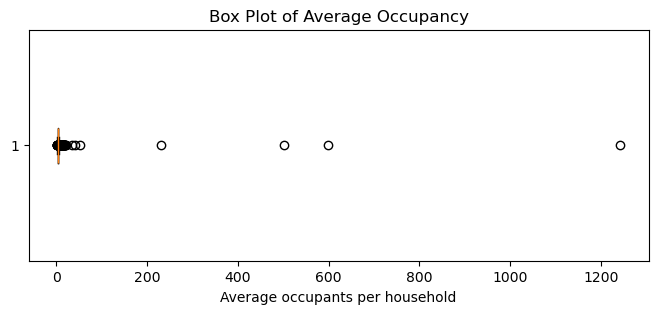

In [22]:
print(train_df["AveOccup"].describe())

plt.figure(figsize=(8, 3))
plt.boxplot(train_df["AveOccup"], vert=False)
plt.xlabel("Average occupants per household")
plt.title("Box Plot of Average Occupancy")
plt.show()

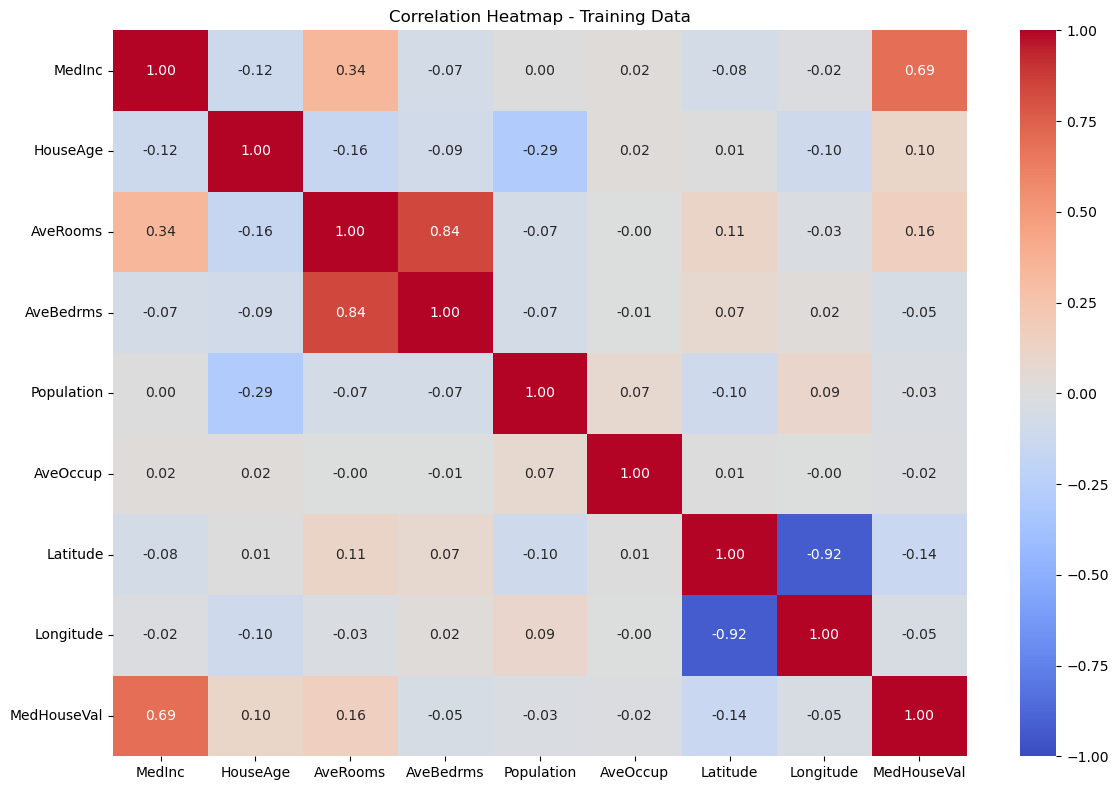

In [24]:
correlation = train_df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation,annot=True,fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1)
plt.title("Correlation Heatmap - Training Data")
plt.tight_layout()
plt.show()

In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [29]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [31]:
y_pred_linear = linear_model.predict(X_test_scaled)
comparison = pd.DataFrame({"Actual": y_test.to_numpy(),"Predicted": y_pred_linear})
comparison.head(9)

,Actual,Predicted
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746


In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

print(f"MSE: {linear_mse:.4f}")
print(f"MAE: {linear_mae:.4f}")
print(f"R²:  {linear_r2:.4f}")

MSE: 0.5559
MAE: 0.5332
R²:  0.5758


In [36]:
tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

In [37]:
tree_mse = mean_squared_error(y_test, y_pred_tree)
tree_mae = mean_absolute_error(y_test, y_pred_tree)
tree_r2 = r2_score(y_test, y_pred_tree)
print(f"Decision Tree MSE: {tree_mse:.4f}")
print(f"Decision Tree MAE: {tree_mae:.4f}")
print(f"Decision Tree R²:  {tree_r2:.4f}")

Decision Tree MSE: 0.4952
Decision Tree MAE: 0.4547
Decision Tree R²:  0.6221


In [39]:
forest_model = RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)
forest_model.fit(X_train, y_train)
y_pred_forest = forest_model.predict(X_test)

In [40]:
forest_mse = mean_squared_error(y_test, y_pred_forest)
forest_mae = mean_absolute_error(y_test, y_pred_forest)
forest_r2 = r2_score(y_test, y_pred_forest)
print(f"Random Forest MSE: {forest_mse:.4f}")
print(f"Random Forest MAE: {forest_mae:.4f}")
print(f"Random Forest R²:  {forest_r2:.4f}")

Random Forest MSE: 0.2554
Random Forest MAE: 0.3275
Random Forest R²:  0.8051


In [42]:

boost_model = GradientBoostingRegressor(n_estimators=100,learning_rate=0.1,max_depth=3,random_state=42)
boost_model.fit(X_train, y_train)
y_pred_boost = boost_model.predict(X_test)

In [43]:
# Evaluate Gradient Boosting predictions
boost_mse = mean_squared_error(y_test, y_pred_boost)
boost_mae = mean_absolute_error(y_test, y_pred_boost)
boost_r2 = r2_score(y_test, y_pred_boost)

print(f"Gradient Boosting MSE: {boost_mse:.4f}")
print(f"Gradient Boosting MAE: {boost_mae:.4f}")
print(f"Gradient Boosting R²:  {boost_r2:.4f}")

Gradient Boosting MSE: 0.2940
Gradient Boosting MAE: 0.3716
Gradient Boosting R²:  0.7756


In [45]:
svr_model = SVR(kernel="rbf",C=1.0,epsilon=0.1)
svr_model.fit(X_train_scaled, y_train)
y_pred_svr = svr_model.predict(X_test_scaled)


In [46]:
svr_mse = mean_squared_error(y_test, y_pred_svr)
svr_mae = mean_absolute_error(y_test, y_pred_svr)
svr_r2 = r2_score(y_test, y_pred_svr)
print(f"SVR MSE: {svr_mse:.4f}")
print(f"SVR MAE: {svr_mae:.4f}")
print(f"SVR R²:  {svr_r2:.4f}")

SVR MSE: 0.3570
SVR MAE: 0.3986
SVR R²:  0.7276


In [47]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "SVR"
    ],
    "MSE": [
        linear_mse, tree_mse, forest_mse, boost_mse, svr_mse
    ],
    "MAE": [
        linear_mae, tree_mae, forest_mae, boost_mae, svr_mae
    ],
    "R2": [
        linear_r2, tree_r2, forest_r2, boost_r2, svr_r2
    ]
})

results = results.sort_values("MSE").reset_index(drop=True)
results.round(4)

,Model,MSE,MAE,R2
0,Random Forest,0.2554,0.3275,0.8051
1,Gradient Boosting,0.2940,0.3716,0.7756
2,SVR,0.3570,0.3986,0.7276
3,Decision Tree,0.4952,0.4547,0.6221
4,Linear Regression,0.5559,0.5332,0.5758


In [49]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

cv = KFold(n_splits=5, shuffle=True, random_state=42)

linear_pipeline = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_cv_scores = cross_val_score(
    linear_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="r2"
)

print("R² for each fold:", linear_cv_scores.round(4))
print(f"Mean CV R²: {linear_cv_scores.mean():.4f}")
print(f"Standard deviation: {linear_cv_scores.std():.4f}")

R² for each fold: [0.6097 0.6041 0.6354 0.6008 0.6073]
Mean CV R²: 0.6115
Standard deviation: 0.0124


In [50]:
tree_cv_scores = cross_val_score(
    DecisionTreeRegressor(random_state=42),
    X_train,
    y_train,
    cv=cv,
    scoring="r2"
)

print("R² for each fold:", tree_cv_scores.round(4))
print(f"Mean CV R²: {tree_cv_scores.mean():.4f}")
print(f"Standard deviation: {tree_cv_scores.std():.4f}")

R² for each fold: [0.5843 0.6433 0.5941 0.5903 0.5743]
Mean CV R²: 0.5973
Standard deviation: 0.0240


In [51]:
forest_cv_scores = cross_val_score(
    RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    X_train,
    y_train,
    cv=cv,
    scoring="r2"
)

print("R² for each fold:", forest_cv_scores.round(4))
print(f"Mean CV R²: {forest_cv_scores.mean():.4f}")
print(f"Standard deviation: {forest_cv_scores.std():.4f}")

R² for each fold: [0.8003 0.8127 0.809  0.7955 0.8054]
Mean CV R²: 0.8045
Standard deviation: 0.0061


In [52]:
boost_cv_scores = cross_val_score(
    GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),
    X_train,
    y_train,
    cv=cv,
    scoring="r2"
)

print("R² for each fold:", boost_cv_scores.round(4))
print(f"Mean CV R²: {boost_cv_scores.mean():.4f}")
print(f"Standard deviation: {boost_cv_scores.std():.4f}")

R² for each fold: [0.7856 0.7889 0.7989 0.7779 0.7892]
Mean CV R²: 0.7881
Standard deviation: 0.0068


In [53]:
svr_pipeline = make_pipeline(
    StandardScaler(),
    SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    )
)

svr_cv_scores = cross_val_score(
    svr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="r2"
)

print("R² for each fold:", svr_cv_scores.round(4))
print(f"Mean CV R²: {svr_cv_scores.mean():.4f}")
print(f"Standard deviation: {svr_cv_scores.std():.4f}")

R² for each fold: [0.7434 0.7348 0.7522 0.7232 0.729 ]
Mean CV R²: 0.7365
Standard deviation: 0.0103


In [54]:
cv_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "SVR"
    ],
    "Mean CV R2": [
        linear_cv_scores.mean(),
        tree_cv_scores.mean(),
        forest_cv_scores.mean(),
        boost_cv_scores.mean(),
        svr_cv_scores.mean()
    ],
    "CV Standard Deviation": [
        linear_cv_scores.std(),
        tree_cv_scores.std(),
        forest_cv_scores.std(),
        boost_cv_scores.std(),
        svr_cv_scores.std()
    ]
})

cv_results = cv_results.sort_values(
    "Mean CV R2", ascending=False
).reset_index(drop=True)

cv_results.round(4)

,Model,Mean CV R2,CV Standard Deviation
0,Random Forest,0.8045,0.0061
1,Gradient Boosting,0.7881,0.0068
2,SVR,0.7365,0.0103
3,Linear Regression,0.6115,0.0124
4,Decision Tree,0.5973,0.0240


In [56]:
linear_tuning_pipeline = make_pipeline(
    StandardScaler(),
    LinearRegression()
)


linear_param_grid = {
    "linearregression__fit_intercept": [True, False]
}


linear_search = GridSearchCV(
    estimator=linear_tuning_pipeline,
    param_grid=linear_param_grid,
    scoring="r2",
    cv=cv,
    refit=True
)

linear_search.fit(X_train, y_train)

print("Best parameters:", linear_search.best_params_)
print(f"Best mean CV R²: {linear_search.best_score_:.4f}")

Best parameters: {'linearregression__fit_intercept': True}
Best mean CV R²: 0.6115


In [57]:

tree_param_grid = {
    "max_depth": [None, 5, 10, 15],
    "min_samples_leaf": [1, 5, 10]
}


tree_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=tree_param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=-1,
    refit=True
)

tree_search.fit(X_train, y_train)

print("Best parameters:", tree_search.best_params_)
print(f"Best mean CV R²: {tree_search.best_score_:.4f}")

Best parameters: {'max_depth': 15, 'min_samples_leaf': 10}
Best mean CV R²: 0.7129


In [58]:
forest_param_grid = {
    "max_depth": [None, 15],
    "min_samples_leaf": [1, 2],
    "max_features": [1.0, 0.8]
}

forest_search = GridSearchCV(
    estimator=RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ),
    param_grid=forest_param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=-1,
    refit=True
)

forest_search.fit(X_train, y_train)

print("Best parameters:", forest_search.best_params_)
print(f"Best mean CV R²: {forest_search.best_score_:.4f}")

Best parameters: {'max_depth': None, 'max_features': 0.8, 'min_samples_leaf': 2}
Best mean CV R²: 0.8079


In [59]:
boost_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

boost_search = GridSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_grid=boost_param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=-1,
    refit=True
)

boost_search.fit(X_train, y_train)

print("Best parameters:", boost_search.best_params_)
print(f"Best mean CV R²: {boost_search.best_score_:.4f}")

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best mean CV R²: 0.8094


In [60]:
svr_param_grid = {
    "svr__C": [1.0, 10.0],
    "svr__epsilon": [0.1, 0.2]
}

svr_search = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", gamma="scale")
    ),
    param_grid=svr_param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=1,
    refit=True
)

svr_search.fit(X_train, y_train)

print("Best parameters:", svr_search.best_params_)
print(f"Best mean CV R²: {svr_search.best_score_:.4f}")

Best parameters: {'svr__C': 10.0, 'svr__epsilon': 0.2}
Best mean CV R²: 0.7594


In [61]:

best_model = boost_search.best_estimator_
final_predictions = best_model.predict(X_test)
final_mse = mean_squared_error(y_test, final_predictions)
final_mae = mean_absolute_error(y_test, final_predictions)
final_r2 = r2_score(y_test, final_predictions)

print("Selected model: Tuned Gradient Boosting")
print("Parameters:", boost_search.best_params_)
print(f"Test MSE: {final_mse:.4f}")
print(f"Test MAE: {final_mae:.4f}")
print(f"Test R²:  {final_r2:.4f}")

Selected model: Tuned Gradient Boosting
Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Test MSE: 0.2615
Test MAE: 0.3483
Test R²:  0.8004


## Final Model Selection and Conclusion
Five regression algorithms were evaluated on the California Housing dataset using MSE, MAE, and R². Five-fold cross-validation and GridSearchCV were performed on the training set.
Tuned Gradient Boosting was selected because it achieved the highest mean cross-validation R² among the tested configurations (0.8094), slightly above tuned Random Forest (0.8079). Its selected parameters were n_estimators=200, learning_rate=0.1, and max_depth=3.
On the test set, the selected model achieved an MSE of 0.2615, MAE of 0.3483, and R² of 0.8004. The MAE corresponds to approximately $34,830. Its sequential correction of errors and ability to model nonlinear relationships provide a plausible explanation for its strong performance.
Baseline Random Forest had a slightly higher test R² of 0.8051. Therefore, Gradient Boosting is the selected model under the cross-validation criterion, rather than a clear winner on every metric. The test set had also been used for baseline reporting; hyperparameter selection was based on training-set cross-validation.